# Entrenamiento del detector de matrículas

En este cuaderno se entrena el detector de matrículas. Se entrenan los modelos `RT-DETRv4-L` y `YOLO26-X` partiendo de sus pesos de COCO. Ambos modelos detectan una única clase, `plate`, sobre los recortes de vehículos generados en [`build_vehicle_dataset.ipynb`](./build_vehicle_dataset.ipynb). Su evaluación y la comparación se encuentran [`plates_module2_comparative.ipynb`](../plates_module2_comparative.ipynb).

## Entrenamiento
Los dos modelos se entrenan en las mismas condiciones:

- **Datos:** se entrenan con datos de `data/vehicles/train`. Al final de cada época, se evalúa el modelo con las imágenes de validación (`data/vehicles/val`).
- **Épocas:** hasta 200, con _early stopping_: el entrenamiento se para si el mAP@50-95 de validación no mejora en 20 épocas seguidas, guardándose el modelo con la mejor época.
- **Tamaño de _batch_:** 12 imágenes
- **_Data augmentation_:** el proporcionado por cada modelo (mosaico, _flips_, cambios de color, cambios de escala,...).
- **Monitorización del rendimiento:** pérdida, _learning rate_, métricas de validación de cada época en _TensorBoard_.

## Índice

1. [Preparación](#1-preparación)
    - [1.1 Configuración](#11-configuración)
    - [1.2 Información del equipo](#12-información-del-equipo)
2. [Conjunto de datos](#2-conjunto-de-datos)
3. [Entrenamiento](#3-entrenamiento)
    - [3.1 Ejecución independiente](#31-ejecución-independiente)
    - [3.2 YOLO26-X](#32-yolo26-x)
    - [3.3 RT-DETRv4-L](#33-rt-detrv4-l)
    - [3.4 Métricas de entrenamiento](#34-métricas-de-entrenamiento)

## 1. Preparación

### 1.1 Configuración

In [ ]:
import json
import math
import os
import shutil
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import yaml
from PIL import Image
from ultralytics import settings

sys.path.insert(0, "..")
from common.detr import coco_config, get_repo, get_weights, use_repo_engine
from common.paths import PLATES_DATA, PLATES_MODULE, PLATES_RUNS, WEIGHTS
from common.specs import save_system_info

Rutas del _dataset_ y de los resultados de cada entrenamiento. Las rutas comunes a todos los cuadernos están en [`common/paths.py`](../common/paths.py):

In [ ]:
DATA = PLATES_DATA
RUNS = PLATES_RUNS
YOLO_RUN = RUNS / "yolo26x"
RTDETR_RUN = RUNS / "rtdetrv4_l"

RUNS.mkdir(parents=True, exist_ok=True)

Parámetros del entrenamiento:

- `EPOCHS` y `PATIENCE`: número máximo de épocas y número de épocas sin mejora a esperar antes de realizar _early stopping_.
- `BATCH` e `IMAGE_SIZE`: tamaño del _batch_ y resolución de las imágenes de entrada.
- `WARMUP_IMAGES`: número de imágenes de calentamiento. Durante estas, el _learning rate_ sube lentamente desde cero, para evitar deteriorar los pesos de COCO.
- `WORKERS`: número de procesos en paralelo.
- `SEED`: semilla, para que los entrenamientos sean reproducibles.
- `FORCE`: si es `False` y un modelo ya está entrenado, se reutilizan sus pesos en lugar de volver a entrenarlo.

In [ ]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 200
PATIENCE = 20
BATCH = 12
IMAGE_SIZE = 640
WARMUP_IMAGES = 8000
WORKERS = 4
SEED = 0
FORCE = False

WARMUP_ITERS = WARMUP_IMAGES // BATCH

print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(sin GPU)")

device: cuda NVIDIA GeForce RTX 5080


### 1.2 Información del equipo

Los tiempos de entrenamiento dependen del equipo, por lo que se guarda esta información en `system_info.json` (ver funciones en [`specs.py`](../common/specs.py)):

In [ ]:
PACKAGES = ["torch", "torchvision", "ultralytics", "faster-coco-eval", "opencv-python", "numpy", "pandas"]

save_system_info(RUNS / "system_info.json", PACKAGES)

{'os': 'Windows-10-10.0.26200-SP0',
 'cpu': 'AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD',
 'cpu_cores': 8,
 'ram_gb': 34.0,
 'python': '3.11.18',
 'gpu': 'NVIDIA GeForce RTX 5080',
 'gpu_driver': '610.88',
 'cuda': '13.0',
 'packages': {'torch': '2.14.1+cu130',
  'torchvision': '0.29.1+cu130',
  'ultralytics': '8.4.202',
  'faster-coco-eval': '1.8.0',
  'opencv-python': '4.10.0.84',
  'numpy': '2.3.5',
  'pandas': '3.1.1'}}

## 2. Conjunto de datos

Ambos modelos utilizan las mismas imágenes, pero esperan las anotaciones en distinto formato. Esto obliga a _parsear_ las anotaciones procedentes del _dataset_ a 2 estructuras distintas:

- **Formato YOLO** (modelos YOLO): un fichero `data.yaml` general con las rutas a los conjuntos, y un fichero `.txt` por cada imagen, que contiene 1 línea por matrícula presente en la imagen. Cada línea sigue el formato `clase x_center y_center width height`, con valores de posición relativos, entre 0 y 1.
- **Formato COCO** (modelos RT-DETRv4): un `coco.json` por conjunto, con todas las imágenes y las cajas `[x, y, width, height]` en píxeles. 

In [ ]:
SPLITS = ("train", "val", "test")


def read_plates(split, image_path):
    return json.load(open(DATA / split / "annotations" / f"{image_path.stem}.json", encoding="utf-8"))


def coco_annotation(plate, ann_id, image_id, width, height):
    cx, cy, w, h = plate["rectangle"]
    return {"id": ann_id, "image_id": image_id, "category_id": 0, "iscrowd": 0, "plate": plate["plate"],
            "bbox": [(cx - w / 2) * width, (cy - h / 2) * height, w * width, h * height], "area": w * width * h * height}

Conversión de las anotaciones de cada conjunto (el reparto en _train_, _val_ y _test_ se hace en [`build_vehicle_dataset.ipynb`](./build_vehicle_dataset.ipynb)):

In [ ]:
def convert_split(split):
    (DATA / split / "labels").mkdir(exist_ok=True)
    images, annotations = [], []
    for path in sorted((DATA / split / "images").iterdir()):
        width, height = Image.open(path).size
        plates = read_plates(split, path)
        (DATA / split / "labels" / f"{path.stem}.txt").write_text("".join(f"0 {cx} {cy} {w} {h}\n" for cx, cy, w, h in (p["rectangle"] for p in plates)))

        image_id = len(images) + 1
        images.append({"id": image_id, "file_name": path.name, "width": width, "height": height})
        annotations += [coco_annotation(p, len(annotations) + i + 1, image_id, width, height) for i, p in enumerate(plates)]

    coco = {"images": images, "annotations": annotations, "categories": [{"id": 0, "name": "plate"}]}
    json.dump(coco, open(DATA / split / "coco.json", "w"))
    print(f"{split}: {len(images)} recortes, {len(annotations)} matrículas")
    return len(images)

In [ ]:
N_IMAGES = {split: convert_split(split) for split in SPLITS}
yaml.safe_dump({"path": str(DATA), "train": "train/images", "val": "val/images", "test": "test/images", "names": {0: "plate"}},
               open(DATA / "data.yaml", "w"))

ITERS_PER_EPOCH = math.ceil(N_IMAGES["train"] / BATCH)
print(f"{ITERS_PER_EPOCH} iteraciones por época, warmup de {WARMUP_ITERS} iteraciones")

train: 6083 recortes, 4258 matrículas


val: 1358 recortes, 931 matrículas


test: 1256 recortes, 894 matrículas
507 iteraciones por época, warmup de 666 iteraciones


## 3. Entrenamiento

### 3.1 Ejecución independiente

Cada entrenamiento se lanza en un proceso independiente, por dos motivos:

- El cuaderno no ocupa memoria de la GPU, y cada modelo dispone de la GPU entera.
- En Windows, la carga de imágenes en paralelo no funciona si se lanza desde una celda del cuaderno, al requerir la carga de un programa.

La salida completa del entrenamiento se guarda en `train.log`, para poder mostrarla y analizarla posteriormente:

In [ ]:
def run_process(cmd, log_file, cwd=None):
    env = {**os.environ, "PYTHONUNBUFFERED": "1"}
    with open(log_file, "w", encoding="utf-8") as log, \
         subprocess.Popen(cmd, cwd=cwd, env=env, text=True, encoding="utf-8", errors="replace",
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT) as proc:
        for line in proc.stdout:
            log.write(line)
            if "━" not in line or "100%" in line:
                print(line[:250].rstrip())
    if proc.returncode != 0:
        raise RuntimeError(f"El proceso terminó con código {proc.returncode}: ver {log_file}")

### 3.2 YOLO26-X

YOLO26-X se entrena con el comando `yolo` de Ultralytics, que ya incluye el _early stopping_ (`patience`), el registro en TensorBoard y el aumento de datos. Ultralytics cuenta el _warmup_ en épocas, por lo que se calculan el número de épocas correspondientes a `WARMUP_ITERS`. Se guardan los pesos de la mejor época (`best.pt`) y de la última (`last.pt`):

In [ ]:
def train_yolo():
    args = {"model": WEIGHTS / "yolo26x.pt", "data": DATA / "data.yaml", "epochs": EPOCHS, "patience": PATIENCE,
            "batch": BATCH, "imgsz": IMAGE_SIZE, "warmup_epochs": round(WARMUP_ITERS / ITERS_PER_EPOCH, 4), "workers": WORKERS,
            "seed": SEED, "deterministic": True, "project": RUNS, "name": YOLO_RUN.name, "exist_ok": True}
    settings.update({"tensorboard": True})
    shutil.rmtree(YOLO_RUN, ignore_errors=True)
    YOLO_RUN.mkdir(parents=True)
    yolo = Path(sys.executable).with_name("yolo.exe")
    run_process([str(yolo), "detect", "train", *(f"{k}={v}" for k, v in args.items())], YOLO_RUN / "train.log")

In [ ]:
if FORCE or not (YOLO_RUN / "weights" / "best.pt").exists():
    train_yolo()

### 3.3 RT-DETRv4-L

RT-DETRv4 se entrena con el `train.py` de su repositorio, a partir de su configuración oficial para COCO, que se adapta en varios pasos.

1. Se carga la configuración del modelo L y se elimina DINOv3. El repositorio lo utiliza para mejorar el entrenamiento en COCO, pero el modelo es grande, y no cabría en la GPU junto a RT-DETRv4-L.

In [ ]:
REPO = get_repo("rtdetrv4")
use_repo_engine("rtdetrv4")
from engine.core.yaml_utils import load_config


def official_config():
    cfg = load_config(str(coco_config("rtdetrv4", "l")), {})
    for key in ("__include__", "teacher_model"):
        cfg.pop(key, None)
    return cfg

2. El entrenamiento oficial de RT-DETRv4 está pensado para durar 58 épocas, con configuraciones específicas de _learning rate_ y de _data augmentation_. Para no perder el _pipeline_ propuesto por los creadores del modelo, se adapta al número de épocas del nuevo modelo a entrenar:

In [ ]:
def rescale_epochs(cfg, epochs=EPOCHS):
    r = epochs / cfg["epoches"]
    train_dl = cfg["train_dataloader"]
    policy = train_dl["dataset"]["transforms"]["policy"]
    policy["epoch"] = [int(e * r) for e in policy["epoch"]]
    collate = train_dl["collate_fn"]
    collate.update(mixup_epochs=[int(e * r) for e in collate["mixup_epochs"]], stop_epoch=int(collate["stop_epoch"] * r))
    cfg.update(epoches=epochs, flat_epoch=int(cfg["flat_epoch"] * r), no_aug_epoch=int(cfg["no_aug_epoch"] * r))

3. Se adapta la configuración del modelo al nuevo caso:
    - Una única clase (`plate`), sin traducir a las clases de COCO.
    - `WARMUP_ITERS`: iteraciones de calentamiento.
    - Rutas de las imágenes y anotaciones.
    - Carpeta de resultados y de TensorBoard.
    - Pesos guardados: se guardan los pesos de la mejor y de la última época.
    - El _learning rate_ oficial está fijado para _batch_ 32, por lo que se escala proporcionalmente a `BATCH`.


In [ ]:
def set_training(cfg):
    cfg.update(num_classes=1, remap_mscoco_category=False, warmup_iter=WARMUP_ITERS, checkpoint_freq=10**6,
               output_dir=str(RTDETR_RUN), summary_dir=str(RTDETR_RUN / "summary"))
    for loader, split in (("train_dataloader", "train"), ("val_dataloader", "val")):
        cfg[loader]["dataset"].update(img_folder=str(DATA / split / "images"), ann_file=str(DATA / split / "coco.json"))
        cfg[loader].update(total_batch_size=BATCH, num_workers=WORKERS)
    for group in (cfg["optimizer"], cfg["optimizer"]["params"][0]):
        group["lr"] *= BATCH / 32


def rtdetr_config():
    cfg = official_config()
    rescale_epochs(cfg)
    set_training(cfg)
    return cfg

El `train.py` se lanza a través de [`train_rtdetr.py`](./train_rtdetr.py), que añade la información restante para el entrenamiento:

- Corrige los _position embeddings_, que el repositorio deja en la CPU y hacen fallar la validación en la GPU.
- Añade el _early stopping_ con `PATIENCE` épocas.
- Guarda `last.pth` al terminar.

Las métricas de validación de cada época se guardan también en `results.csv`, con el mismo formato que el de YOLO:

In [ ]:
COCO_STATS = ["mAP50-95", "mAP50", "mAP75", "mAP_small", "mAP_medium", "mAP_large",
              "AR1", "AR10", "AR100", "AR_small", "AR_medium", "AR_large"]


def train_rtdetr(cfg):
    shutil.rmtree(RTDETR_RUN, ignore_errors=True)
    RTDETR_RUN.mkdir(parents=True)
    yaml.safe_dump(cfg, open(RTDETR_RUN / "config.yml", "w"), sort_keys=False)
    cmd = [sys.executable, str(PLATES_MODULE / "train_rtdetr.py"), str(REPO), str(PATIENCE), "-c", str(RTDETR_RUN / "config.yml"),
           "-t", str(get_weights("rtdetrv4", "l")), "--use-amp", "--seed", str(SEED)]
    run_process(cmd, RTDETR_RUN / "train.log", cwd=REPO)


def epoch_row(entry):
    row = {"epoch": entry["epoch"], **{k: v for k, v in entry.items() if k.startswith("train_")}}
    row.update({f"val_{s}": v for s, v in zip(COCO_STATS, entry["test_coco_eval_bbox"])})
    return row


def log_to_csv(run):
    entries = [json.loads(line) for line in open(run / "log.txt")]
    pd.DataFrame([epoch_row(e) for e in entries]).to_csv(run / "results.csv", index=False)

In [ ]:
if FORCE or not (RTDETR_RUN / "last.pth").exists():
    train_rtdetr(rtdetr_config())
log_to_csv(RTDETR_RUN)

### 3.4 Métricas de entrenamiento

Mejor época de cada modelo, según el mAP@50-95 de validación, que es la que se guarda como mejor modelo. YOLO numera las épocas desde 1 y RT-DETRv4 desde 0:

In [ ]:
def val_curves():
    yolo = pd.read_csv(YOLO_RUN / "results.csv").rename(columns=str.strip)
    rtdetr = pd.read_csv(RTDETR_RUN / "results.csv")
    return {"yolo26x": yolo.rename(columns={"metrics/mAP50-95(B)": "mAP50-95", "metrics/mAP50(B)": "mAP50"}),
            "rtdetrv4-l": rtdetr.rename(columns={"val_mAP50-95": "mAP50-95", "val_mAP50": "mAP50"})}


def best_epoch(name, df):
    best = df.loc[df["mAP50-95"].idxmax()]
    return {"modelo": name, "épocas": len(df), "mejor época": int(best["epoch"]),
            "mAP50-95 (val)": best["mAP50-95"], "mAP50 (val)": best["mAP50"]}


CURVES = val_curves()
pd.DataFrame([best_epoch(name, df) for name, df in CURVES.items()]).round(3)

,modelo,épocas,mejor época,mAP50-95 (val),mAP50 (val)
0,yolo26x,111,91,0.808,0.962
1,rtdetrv4-l,83,62,0.842,0.967


Evolución del mAP@50-95 de validación en cada época. La línea discontinua marca la mejor época de cada modelo:

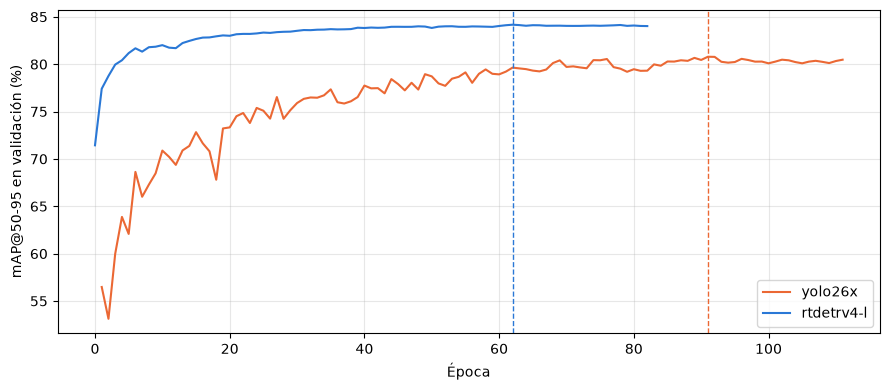

In [ ]:
COLORS = {"yolo26x": "#eb6834", "rtdetrv4-l": "#2a78d6"}

fig, ax = plt.subplots(figsize=(9, 4))
for name, df in CURVES.items():
    ax.plot(df["epoch"], 100 * df["mAP50-95"], color=COLORS[name], label=name)
    ax.axvline(df.loc[df["mAP50-95"].idxmax(), "epoch"], color=COLORS[name], linestyle="--", linewidth=1)
ax.set_xlabel("Época")
ax.set_ylabel("mAP@50-95 en validación (%)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(RUNS / "map_val.png", dpi=150)
plt.show()

RT-DETRv4-L alcanzó su mejor mAP@50-95 de validación (0,842) en la época 62, y YOLO26-X (0,808) en la 91. Ambos se pararon por _early stopping_. La comparación de los dos modelos se recoge en [`plates_module2_comparative.ipynb`](../plates_module2_comparative.ipynb).